In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
import cartopy.util as cutil
import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP

### FIRST LET'S CREATE A MASK OVER GREENLAND

### MASK 1
A mask with the shape of greenland

In [2]:
if False:

    # Load the world shapefile from GeoPandas datasets
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    
    # Filter the dataset to only include Greenland
    greenland = world[world['name'] == 'Greenland'].explode(index_parts=False)
    
    # Define the resolution and create a grid of latitudes and longitudes
    lat_resolution = 2.5  # Resolution of 2.5 degrees
    lon_resolution = 2.5  # Resolution of 2.5 degrees
    
    # Define latitude and longitude ranges (rough bounds around Greenland)
    latitudes = np.arange(0, 91, lat_resolution)
    longitudes = np.arange(-180, +180, lon_resolution)
    
    # Initialize a mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Create the mask: 1 inside Greenland, 0 outside
    for i, lat in enumerate(latitudes):
        for j, lon in enumerate(longitudes):
            point = Point(lon, lat)
            if any(greenland.contains(point)):
                mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

### MASK 2
A mask with rectangular shape

In [3]:
if True:

    # Define the resolution
    lat_resolution = 2.5  # 2.5 degrees
    lon_resolution = 2.5  # 2.5 degrees
    
    # Define the global latitude and longitude ranges
    latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
    longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E
    
    # Initialize a global mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
    lat_min, lat_max = 60, 80
    lon_min, lon_max = -80, -20
    
    # Assign 1 to grid points within the bounding box
    for i, lat in enumerate(latitudes):
        if lat_min <= lat <= lat_max:
            for j, lon in enumerate(longitudes):
                if lon_min <= lon <= lon_max:
                    mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

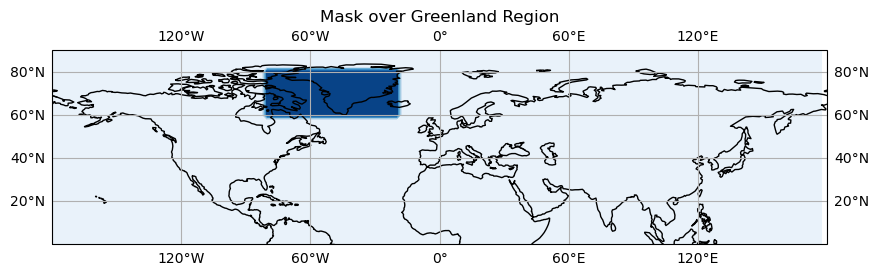

In [4]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr, cmap='Blues', transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
plt.title('Mask over Greenland Region')

# Show the plot
plt.show()

### IMPORT BLOCKING DATA AND COMPUTE FREQUENCY

In [5]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960.nc
dictionaries


In [6]:
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')
ds_filt_MIX = xr.open_dataset('ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc')
#Greenland coordinates
#convert the tracked DAV into a boolean matrix
DAV = xr.where(ds_filt_DAV['DAV_tracked']>0,1,0)
GHA = xr.where(ds_filt_GHA['GHA_tracked']>0,1,0)
MIX = xr.where(ds_filt_MIX['MIX_tracked']>0,1,0)
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']

In [7]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    #print(len(new_data))
    return new_data

In [9]:
count_DAV = 0
count_GHA = 0
count_MIX = 0
count_m = 0
freq_per_month_DAV = []
freq_per_month_GHA = []
freq_per_month_MIX = []
months = ['06','07','08']
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV.values[t,mask_bool]
    GHA_gr = GHA.values[t,mask_bool]
    MIX_gr = MIX.values[t,mask_bool]
    #print(DAV_gr)
    month = str(time.values)[5:7]
    if month in months:
        '''
        #method1
        count_m += mask_size
        count_DAV += np.sum(DAV_gr,axis=(0))
        count_GHA += np.sum(GHA_gr,axis=(0))
        count_MIX += np.sum(MIX_gr,axis=(0))
        '''
        #method2
        count_m += 1
        count_DAV += np.any(DAV_gr>0)
        count_GHA += np.any(GHA_gr>0)
        count_MIX += np.any(MIX_gr>0)
        
        if month != tmp:
            #print(count_m)
            #print(count)
            tmp = month
            freq_per_month_DAV.append(count_DAV/count_m)
            freq_per_month_GHA.append(count_GHA/count_m)
            freq_per_month_MIX.append(count_MIX/count_m)
            count_DAV = 0
            count_GHA = 0
            count_MIX = 0
            count_m = 0

30681it [00:06, 5028.13it/s]


In [10]:
def fit_with_bootstrap(freq_per_month,months,N_it):
    pends = []
    count = 0
    for i in range(N_it):
        tmp = np.random.choice(freq_per_month, size=len(freq_per_month),replace=False)
        coefficients = np.polyfit(months, tmp, 1)
        pend = coefficients[0]
        pends.append(pend)
    coefficients = np.polyfit(months, freq_per_month, 1)
    pend_exp = coefficients[0]
    for pend in pends:
        if abs(pend) > abs(pend_exp):
            count += 1
    p_value = count/N_it
    return pend_exp,p_value

In [11]:
#NORMALIZE THE TIME SERIES
for list in (freq_per_month_DAV,freq_per_month_GHA,freq_per_month_MIX):
    mean = np.mean(list[10*len(months):60*len(months)])
    std_dev = np.std(list[10*len(months):60*len(months)])
    for i,l in enumerate(list):
        list[i] = (l-mean)/std_dev

DAV
0.003034508178466435 0.001
GHA
0.0009873829195105024 0.279
MIX
0.0007010754247476792 0.46


Text(0.5, 1.0, '(c) MIX')

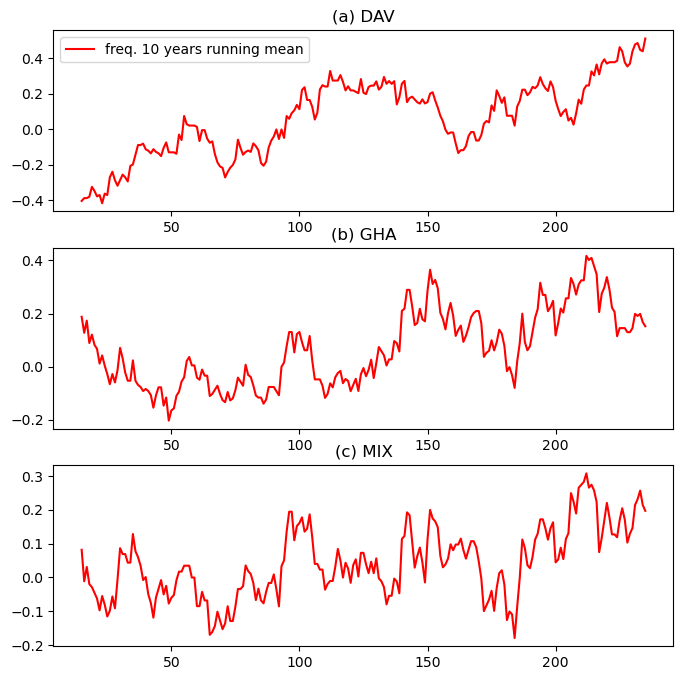

In [12]:
window = 10*len(months)
freq_per_month_run_avg_DAV = running_mean(freq_per_month_DAV,window)
freq_per_month_run_avg_GHA = running_mean(freq_per_month_GHA,window)
freq_per_month_run_avg_MIX = running_mean(freq_per_month_MIX,window)
years = np.arange(1940,2024,1)
months_list = np.arange(0,len(freq_per_month_DAV),1)
months_run_avg = months_list[int(window/2):int(-window/2)]

# Fit linear regression model with errors
pend,p_value = fit_with_bootstrap(freq_per_month_DAV,months_list,2000)
print('DAV')
print(pend,p_value)
pend,p_value = fit_with_bootstrap(freq_per_month_GHA,months_list,2000)
print('GHA')
print(pend,p_value)
pend,p_value = fit_with_bootstrap(freq_per_month_MIX,months_list,2000)
print('MIX')
print(pend,p_value)

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8, 8))

#axes[0].plot(months_list,freq_per_month_DAV,color='black',label='freq. per month')
axes[0].plot(months_run_avg,freq_per_month_run_avg_DAV,color='r',label='freq. 10 years running mean')
axes[0].set_title('(a) DAV')
axes[0].legend()

#axes[1].plot(months_list,freq_per_month_GHA,color='black',label='freq. per month')
axes[1].plot(months_run_avg,freq_per_month_run_avg_GHA,color='r',label='freq. 10 years running mean')
axes[1].set_title('(b) GHA')

#axes[1].plot(months_list,freq_per_month_GHA,color='black',label='freq. per month')
axes[2].plot(months_run_avg,freq_per_month_run_avg_MIX,color='r',label='freq. 10 years running mean')
axes[2].set_title('(c) MIX')


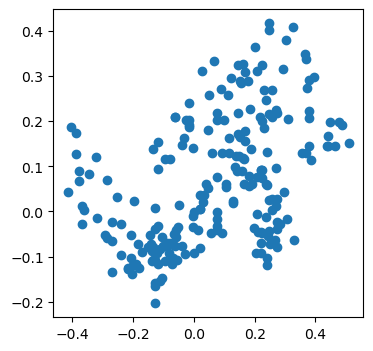

In [13]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4, 4))
plt.scatter(freq_per_month_run_avg_DAV,freq_per_month_run_avg_GHA)